# 📚 BiblioLLM — Entrenamiento del modelo propio (Unicórdoba)

**Qué hace este notebook** (≈50–60 min en Colab con GPU T4 gratis):

1. Carga el dataset generado a partir del catálogo real de las 3 bibliotecas
   (Central–Montería, Lorica, Berástegui).
2. Mide qué tan bien responde el modelo base **antes** de entrenar.
3. **Afina (fine-tuning) con LoRA** el LLM abierto `Qwen2.5-0.5B-Instruct`
   para que aprenda a responder como bibliotecario usando SOLO las fichas.
4. Lo vuelve a medir **después** (tabla comparativa para la sustentación).
5. Fusiona LoRA y lo sube a tu Hugging Face en dos formatos: **GGUF** para tu
   servidor (tu PC o Cloud Run: los usuarios no descargan nada) y **ONNX 4 bits**
   (opcional, para correrlo dentro del navegador).

**Antes de empezar:** `Entorno de ejecución → Cambiar tipo de entorno → GPU T4`.

¿Por qué fine-tuning + RAG y no solo fine-tuning? Porque el inventario cambia
cada minuto (préstamos, devoluciones, libros nuevos). Si el modelo "memoriza"
el catálogo, queda desactualizado y además inventa. Aquí el modelo aprende
**la habilidad** (leer fichas y responder bien) y los **datos** llegan en vivo
desde Firestore en cada pregunta.

In [1]:
# ⚙️ CONFIGURACIÓN — edita solo esta celda
import os
REPO_GIT = "https://github.com/lcontrerasrada-spec/bibliollm.git"
HF_REPO = "bibliollm-qwen0.5b-unicordoba"   # nombre del modelo en tu cuenta de Hugging Face
MODELO_BASE = "Qwen/Qwen2.5-0.5B-Instruct"
EPOCAS = 2               # 1 = ~20 min, 2 = ~40 min (mejor calidad)
LR = 2e-4
LORA_R, LORA_ALPHA = 16, 32
MAX_LEN = 1024
N_EVAL = 60              # preguntas de evaluación antes/después
EXPORTAR_ONNX = False    # True solo si quieres además la versión que corre en el navegador (+10 min)
SMOKE = os.environ.get("BIBLIOLLM_SMOKE") == "1"  # prueba rápida en CPU (no tocar en Colab)

## 1. Instalar librerías (versiones fijadas y probadas)

In [2]:
import subprocess, sys
if not SMOKE:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "transformers==4.48.3", "peft==0.14.0", "trl==0.14.0", "datasets==3.2.0",
                    "accelerate==1.3.0", "huggingface_hub>=0.27"], check=True)

## 2. Traer el proyecto (dataset + código)
Opción A: pon la URL de tu repositorio en `REPO_GIT`.
Opción B: deja `REPO_GIT` vacío y sube el **zip del proyecto** cuando te lo pida.

In [3]:
import glob, zipfile
if SMOKE:
    PROY = os.path.dirname(os.path.dirname(os.path.abspath("__file__"))) if "__file__" in dir() else os.getcwd()
    PROY = os.environ.get("BIBLIOLLM_DIR", PROY)
elif os.path.exists("/content/bibliollm"):
    PROY = "/content/bibliollm"
elif REPO_GIT:
    subprocess.run(["git", "clone", "-q", REPO_GIT, "/content/bibliollm"], check=True)
    PROY = "/content/bibliollm"
else:
    from google.colab import files
    subido = files.upload()  # sube bibliollm.zip
    nombre = next(iter(subido))
    with zipfile.ZipFile(nombre) as z:
        z.extractall("/content")
    PROY = os.path.dirname(glob.glob("/content/**/entrenamiento/dataset/train.jsonl", recursive=True)[0])
    PROY = os.path.dirname(os.path.dirname(PROY))
DATA = os.path.join(PROY, "entrenamiento", "dataset")
print("Proyecto en:", PROY, "| archivos:", os.listdir(DATA))

Proyecto en: /content/bibliollm | archivos: ['train.jsonl', 'val.jsonl', 'eval.jsonl']


## 3. Cargar el dataset
Cada ejemplo tiene 3 mensajes: **system** (rol del asistente), **user** (fichas
recuperadas del catálogo + pregunta) y **assistant** (respuesta correcta,
construida solo con datos de las fichas).

In [4]:
import json
from datasets import Dataset

def leer(nombre):
    with open(os.path.join(DATA, nombre), encoding="utf-8") as f:
        return [json.loads(l) for l in f if l.strip()]

train_raw, val_raw, eval_raw = leer("train.jsonl"), leer("val.jsonl"), leer("eval.jsonl")
if SMOKE:
    train_raw, val_raw, eval_raw = train_raw[:16], val_raw[:4], eval_raw[:3]
    N_EVAL = 3
print(f"train={len(train_raw)}  val={len(val_raw)}  eval={len(eval_raw)}")
from collections import Counter
print(Counter(e["tipo"] for e in train_raw))
print("\nEjemplo:\n", train_raw[0]["messages"][1]["content"][-500:], "\n→", train_raw[0]["messages"][2]["content"])

train=3972  val=172  eval=150
Counter({'titulo': 1135, 'tema': 682, 'disponibilidad': 512, 'opcion': 422, 'ubicacion': 373, 'autor': 370, 'sede': 291, 'no_encontrado': 163, 'charla': 15, 'fuera_dominio': 9})

Ejemplo:
 : 1 disponible
[3] «Evaluación del sistema de monta estacional en ganado romosinuano» | Autor: Martínez García, Enadis de Jesús | Editorial: Universidad de Córdoba. Facultad de Medicina Veterinaria y Zootecnia. Programa de Medicina Veterinaria y Zootecnia, 1998 | Tipo: Tesis y proyectos de grado | Área: 600 - Tecnologías (Ciencias aplicadas) | Clasificación: T.P.M.V.Z.677 | Ubicación: Colección de trabajos de grado | Disponibilidad: Berástegui: 1 disponible

PREGUNTA: más información del libro 1 
→ Aquí tienes los detalles de la opción 1:

📖 **Evaluacion sistematica**
👤 Autor: Stufflebeam, Daniel L.
🏢 Editorial: Paidos, Barcelona, 1989
📚 Tipo: Libro · Área 000 - Generalidades
🔢 Clasificación: 001.433 S929e
📍 Ubicación: Colección general
📦 Disponibilidad: Central (Monterí

## 4. Cargar el modelo base

In [5]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", DISPOSITIVO, torch.cuda.get_device_name(0) if DISPOSITIVO == "cuda" else "")
tok = AutoTokenizer.from_pretrained(MODELO_BASE)
tok.padding_side = "left"
# float32 en memoria + autocast fp16 al entrenar (la T4 no soporta bf16)
modelo = AutoModelForCausalLM.from_pretrained(MODELO_BASE, torch_dtype=torch.float32).to(DISPOSITIVO)
print(f"Parámetros: {modelo.num_parameters()/1e6:.0f} M")

Dispositivo: cuda Tesla T4


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Parámetros: 494 M


## 5. Métricas de evaluación (para la sustentación)
- **Fidelidad**: % de respuestas donde *todos* los títulos mencionados existen en las fichas (no inventa).
- **Disponibilidad exacta**: % de respuestas donde las copias "N disponibles" coinciden con el inventario.
- **Intención**: si no había resultados, ¿lo dijo? Si los había, ¿los mostró?

In [6]:
import re, unicodedata
def norm(s):
    s = unicodedata.normalize("NFD", s or "")
    s = "".join(c for c in s if unicodedata.category(c) != "Mn").lower()
    return re.sub(r"[^a-z0-9ñ ]+", " ", s).strip()

NO_ENC = re.compile(r"no (encontr|aparece|hay coincidencias|figura)|se sale de lo que|solo (puedo|consulto)", re.I)

def generar(mensajes_lote, max_new=220):
    textos = [tok.apply_chat_template(m, tokenize=False, add_generation_prompt=True) for m in mensajes_lote]
    enc = tok(textos, return_tensors="pt", padding=True).to(DISPOSITIVO)
    with torch.no_grad(), torch.autocast(DISPOSITIVO, dtype=torch.float16, enabled=DISPOSITIVO == "cuda"):
        out = modelo.generate(**enc, max_new_tokens=max_new, do_sample=False, pad_token_id=tok.eos_token_id)
    return [tok.decode(o[enc["input_ids"].shape[1]:], skip_special_tokens=True) for o in out]

def evaluar(ejemplos, etiqueta, lote=12):
    modelo.eval()
    res = {"fidelidad": [], "disponibilidad": [], "intencion": []}
    muestras = []
    for i in range(0, len(ejemplos), lote):
        bloque = ejemplos[i:i + lote]
        resp = generar([e["messages"][:2] for e in bloque])
        for e, r in zip(bloque, resp):
            ctx = e["messages"][1]["content"]
            titulos_ctx = [norm(t) for t in re.findall(r"«(.+?)»", ctx.split("PREGUNTA:")[0])]
            citados = [norm(t) for t in re.findall(r"\*\*(.+?)\*\*", r)]
            res["fidelidad"].append(all(any(c and (c in t or t in c) for t in titulos_ctx) for c in citados))
            nums_ref = set(re.findall(r"(\d+) disponibles?", e["messages"][2]["content"]))
            nums_gen = set(re.findall(r"(\d+) disponibles?", r))
            if nums_ref:
                res["disponibilidad"].append(nums_gen <= set(re.findall(r"(\d+) disponibles?", ctx)) and bool(nums_gen))
            esperaba_no = e["tipo"] in ("no_encontrado", "fuera_dominio")
            if e["tipo"] != "charla":
                res["intencion"].append(bool(NO_ENC.search(r)) == esperaba_no)
            muestras.append((e["messages"][1]["content"].split("PREGUNTA:")[-1].strip(), r))
    pct = {k: 100 * sum(v) / max(1, len(v)) for k, v in res.items()}
    print(f"[{etiqueta}] " + " | ".join(f"{k}: {v:.1f}%" for k, v in pct.items()))
    return pct, muestras

eval_sub = eval_raw[:N_EVAL]
metricas_base, muestras_base = evaluar(eval_sub, "Modelo base")
for q, r in muestras_base[:2]:
    print(f"\n❓ {q}\n🤖 {r[:400]}")

/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:628: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:633: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:650: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:628: UserWarni

[Modelo base] fidelidad: 98.3% | disponibilidad: 10.0% | intencion: 91.7%

❓ ¿hay algún ejemplar de vademecun veterinario?
🤖 Hay un ejemplar disponible en la Biblioteca de la Universidad de Córdoba.

❓ ¿qué tienen de James Cunningham?
🤖 James Cunningham es un autor colombiano de ciencia aplicada, especializado en fisiología veterinaria. Su obra "Fisiología veterinaria" se publicó en varias ediciones, incluyendo una edición actualizada en 2003.


## 6. Fine-tuning con LoRA
LoRA congela los 494 M de parámetros originales y entrena matrices pequeñas
(≈1–2 % del total). Solo se calcula la pérdida sobre la **respuesta del
asistente** (no sobre las fichas), así aprende a responder, no a copiar.

In [7]:
from peft import LoraConfig
from trl import SFTConfig, SFTTrainer, DataCollatorForCompletionOnlyLM

tok.padding_side = "right"
ds_train = Dataset.from_list([{"messages": e["messages"]} for e in train_raw])
ds_val = Dataset.from_list([{"messages": e["messages"]} for e in val_raw])

lora = LoraConfig(r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=0.05, bias="none", task_type="CAUSAL_LM",
                  target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"])
colector = DataCollatorForCompletionOnlyLM(response_template="<|im_start|>assistant\n", tokenizer=tok)

cfg = SFTConfig(
    output_dir="/tmp/bibliollm-lora" if SMOKE else "/content/bibliollm-lora",
    num_train_epochs=EPOCAS if not SMOKE else 1,
    max_steps=-1 if not SMOKE else 2,
    per_device_train_batch_size=4 if not SMOKE else 1,
    gradient_accumulation_steps=4 if not SMOKE else 1,
    per_device_eval_batch_size=4,
    learning_rate=LR, lr_scheduler_type="cosine", warmup_ratio=0.03,
    logging_steps=10 if not SMOKE else 1, eval_strategy="steps" if not SMOKE else "no", eval_steps=100,
    save_strategy="no", fp16=DISPOSITIVO == "cuda", max_seq_length=MAX_LEN, packing=False,
    gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": False},
    report_to="none", seed=42,
)
entrenador = SFTTrainer(model=modelo, args=cfg, train_dataset=ds_train, eval_dataset=ds_val,
                        peft_config=lora, data_collator=colector, processing_class=tok)
entrenador.model.print_trainable_parameters()
historial = entrenador.train()
print(historial)

Map:   0%|          | 0/3972 [00:00<?, ? examples/s]

Map:   0%|          | 0/172 [00:00<?, ? examples/s]

`use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497


Step,Training Loss,Validation Loss
100,0.045500,0.044782
200,0.042300,0.034553
300,0.027300,0.031019
400,0.025400,0.029642


TrainOutput(global_step=496, training_loss=0.07249987362733772, metrics={'train_runtime': 2243.0662, 'train_samples_per_second': 3.542, 'train_steps_per_second': 0.221, 'total_flos': 1.181932938410496e+16, 'train_loss': 0.07249987362733772, 'epoch': 1.9949647532729102})


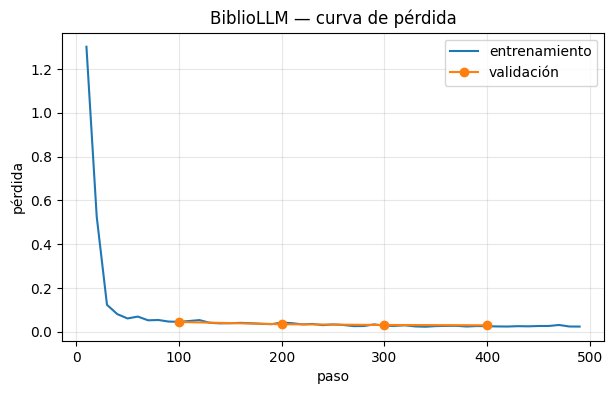

In [8]:
# 📉 Curva de pérdida (para el informe)
import matplotlib
if SMOKE: matplotlib.use("Agg")
import matplotlib.pyplot as plt
logs = entrenador.state.log_history
pt = [(l["step"], l["loss"]) for l in logs if "loss" in l]
pv = [(l["step"], l["eval_loss"]) for l in logs if "eval_loss" in l]
plt.figure(figsize=(7, 4))
if pt: plt.plot(*zip(*pt), label="entrenamiento")
if pv: plt.plot(*zip(*pv), "o-", label="validación")
plt.xlabel("paso"); plt.ylabel("pérdida"); plt.title("BiblioLLM — curva de pérdida"); plt.legend(); plt.grid(alpha=.3)
plt.savefig(os.path.join(PROY, "entrenamiento", "curva_perdida.png"), dpi=150, bbox_inches="tight")
if not SMOKE: plt.show()

## 7. Evaluación después del entrenamiento

In [9]:
modelo = entrenador.model
tok.padding_side = "left"
metricas_ft, muestras_ft = evaluar(eval_sub, "BiblioLLM (afinado)")
import pandas as pd
tabla = pd.DataFrame({"Modelo base": metricas_base, "BiblioLLM afinado": metricas_ft}).round(1)
tabla.index = ["Fidelidad (no inventa títulos) %", "Disponibilidad exacta %", "Intención correcta %"]
print(tabla)
tabla.to_csv(os.path.join(PROY, "entrenamiento", "metricas.csv"))
for (q, rb), (_, rf) in list(zip(muestras_base, muestras_ft))[:3]:
    print(f"\n❓ {q}\n— BASE: {rb[:300]}\n— AFINADO: {rf[:300]}")

/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:628: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:633: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:650: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(


[BiblioLLM (afinado)] fidelidad: 100.0% | disponibilidad: 100.0% | intencion: 96.7%
                                  Modelo base  BiblioLLM afinado
Fidelidad (no inventa títulos) %         98.3              100.0
Disponibilidad exacta %                  10.0              100.0
Intención correcta %                     91.7               96.7

❓ ¿hay algún ejemplar de vademecun veterinario?
— BASE: Hay un ejemplar disponible en la Biblioteca de la Universidad de Córdoba.
— AFINADO: Sí, hay material sobre «vademecun veterinario» (1 en total). Te dejo los más relevantes:

1. **Vademecun Veterinario** (11a. ed., 2002) — clasificación R636.0895 A837vad, Colección referencia.
   ✅ Berástegui: 2 disponibles

¿Te muestro los detalles de alguno? Solo dime el número.

❓ ¿qué tienen de James Cunningham?
— BASE: James Cunningham es un autor colombiano de ciencia aplicada, especializado en fisiología veterinaria. Su obra "Fisiología veterinaria" se publicó en varias ediciones, incluyendo una edició

## 8. Fusionar LoRA y guardar el modelo completo

In [10]:
MERGED = "/tmp/bibliollm-merged" if SMOKE else "/content/bibliollm-merged"
fusionado = modelo.merge_and_unload()
fusionado = fusionado.to(torch.float32)
fusionado.save_pretrained(MERGED, safe_serialization=True)
tok.padding_side = "right"
tok.save_pretrained(MERGED)
print("Guardado en", MERGED, os.listdir(MERGED))

Guardado en /content/bibliollm-merged ['merges.txt', 'special_tokens_map.json', 'model.safetensors', 'vocab.json', 'tokenizer.json', 'generation_config.json', 'tokenizer_config.json', 'added_tokens.json', 'config.json']


## 9. (Opcional) Convertir a ONNX 4 bits para el navegador
`exportar_onnx.py` (en la carpeta `entrenamiento/`) replica el procedimiento del
conversor oficial de Transformers.js y genera:
- `onnx/model_q4f16.onnx` → WebGPU (tarjeta gráfica), el más rápido.
- `onnx/model_q4.onnx` → respaldo para equipos sin WebGPU (CPU/WASM).

In [11]:
del modelo, fusionado, entrenador
import gc; gc.collect()
if DISPOSITIVO == "cuda": torch.cuda.empty_cache()
CARPETA_ONNX = "/tmp/bibliollm-onnx" if SMOKE else "/content/bibliollm-onnx"
if EXPORTAR_ONNX and not SMOKE:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "optimum==1.23.3", "onnx==1.16.2",
                    "onnxruntime==1.20.1", "onnxconverter-common==1.16.0", "onnx-graphsurgeon==0.5.2"], check=True)
    r = subprocess.run([sys.executable, os.path.join(PROY, "entrenamiento", "exportar_onnx.py"), MERGED, CARPETA_ONNX],
                       capture_output=True, text=True)
    print(r.stdout[-3000:]); print(r.stderr[-2000:]) if r.returncode else None
    assert r.returncode == 0, "Falló la exportación a ONNX (mira el error arriba)"

## 10. Crear tu repositorio del modelo en Hugging Face
1. Crea una cuenta en huggingface.co → *Settings → Access Tokens* → token con permiso **Write**.
2. En Colab: ícono 🔑 (Secretos) → agrega `HF_TOKEN` con ese valor y activa el acceso del notebook.

Tu servidor (tu PC o Cloud Run) descarga el modelo desde este repositorio al arrancar.

In [12]:
if not SMOKE:
    from huggingface_hub import HfApi, login
    try:
        from google.colab import userdata
        login(userdata.get("HF_TOKEN"))
    except Exception:
        login()
    api = HfApi()
    usuario = api.whoami()["name"]
    repo_id = f"{usuario}/{HF_REPO}"
    api.create_repo(repo_id, exist_ok=True, private=False)
    os.makedirs(CARPETA_ONNX, exist_ok=True)
    with open(os.path.join(CARPETA_ONNX, "README.md"), "w", encoding="utf-8") as f:
        f.write(f"---\nlibrary_name: transformers.js\nbase_model: {MODELO_BASE}\nlanguage: es\n---\n"
                "# BiblioLLM (Unicórdoba)\nQwen2.5-0.5B-Instruct afinado con LoRA para responder sobre el "
                "catálogo de las bibliotecas de la Universidad de Córdoba usando fichas recuperadas (RAG).\n\n"
                + tabla.to_markdown())
    if EXPORTAR_ONNX:
        api.upload_folder(folder_path=CARPETA_ONNX, repo_id=repo_id, commit_message="BiblioLLM ONNX q4")
        print(f"ONNX subido (modo navegador). En config.js: MODELO_ID: '{repo_id}'")
    else:
        api.upload_file(path_or_fileobj=os.path.join(CARPETA_ONNX, "README.md"), path_in_repo="README.md", repo_id=repo_id)
    print("Repositorio:", f"https://huggingface.co/{repo_id}")

Repositorio: https://huggingface.co/Lucas2209/bibliollm-qwen0.5b-unicordoba


## 11. Versión para el servidor (GGUF 4 bits) — los usuarios NO descargan nada
Convierte el modelo afinado a **GGUF** (formato de llama.cpp) y lo cuantiza a
**Q4_K_M** (4 bits): en la CPU del Space responde ~2 veces más rápido que en 8 bits.
Lo sube al mismo repositorio; tu servidor (tu PC o Cloud Run) lo descarga al arrancar.

In [ ]:
if not SMOKE:
    LLAMA = "/content/llama.cpp"
    if not os.path.exists(LLAMA):
        subprocess.run(["git", "clone", "-q", "--depth", "1", "--branch", "b4600",
                        "https://github.com/ggml-org/llama.cpp", LLAMA], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", os.path.join(LLAMA, "gguf-py"), "sentencepiece"], check=True)
    F16 = "/content/bibliollm-f16.gguf"
    GGUF = "/content/bibliollm-q4_k_m.gguf"
    r = subprocess.run([sys.executable, os.path.join(LLAMA, "convert_hf_to_gguf.py"), MERGED,
                        "--outfile", F16, "--outtype", "f16"], capture_output=True, text=True)
    print(r.stderr[-1200:]); assert r.returncode == 0, "Falló la conversión a GGUF"
    print("Compilando llama-quantize (~3 min)…")
    subprocess.run(["cmake", "-B", "build", "-DGGML_CUDA=OFF", "-DLLAMA_CURL=OFF"], cwd=LLAMA, check=True, capture_output=True)
    subprocess.run(["cmake", "--build", "build", "--target", "llama-quantize", "-j", str(os.cpu_count())],
                   cwd=LLAMA, check=True, capture_output=True)
    r = subprocess.run([os.path.join(LLAMA, "build", "bin", "llama-quantize"), F16, GGUF, "Q4_K_M"], capture_output=True, text=True)
    print(r.stdout[-800:]); assert r.returncode == 0, "Falló la cuantización"
    print(f"GGUF Q4_K_M: {os.path.getsize(GGUF)/1e6:.0f} MB — subiendo…")
    api.upload_file(path_or_fileobj=GGUF, path_in_repo="bibliollm-q4_k_m.gguf", repo_id=repo_id)
    print("\n✅ Listo. En tu PC, dentro de la carpeta del proyecto, arranca el servidor con TU modelo:\n")
    print(f"npm run servidor -- --repo {repo_id} --archivo bibliollm-q4_k_m.gguf\n")
    print("(Solo la primera vez; después basta con: npm run servidor)")
    print("\nSi usas Cloud Run en vez de tu PC, en Cloud Shell:")
    print(f"gcloud run services update bibliollm --region us-central1 --update-env-vars LLAMA_ARG_HF_REPO={repo_id},LLAMA_ARG_HF_FILE=bibliollm-q4_k_m.gguf")


Convirtiendo a GGUF…
   | 430M/988M [00:12<00:12, 45.2Mbyte/s]
Writing:  47%|████▋     | 460M/988M [00:12<00:08, 61.6Mbyte/s]
Writing:  50%|████▉     | 490M/988M [00:12<00:06, 73.6Mbyte/s]
Writing:  52%|█████▏    | 509M/988M [00:13<00:07, 60.1Mbyte/s]
Writing:  53%|█████▎    | 528M/988M [00:13<00:07, 64.1Mbyte/s]
Writing:  55%|█████▍    | 541M/988M [00:15<00:22, 20.0Mbyte/s]
Writing:  59%|█████▊    | 579M/988M [00:16<00:11, 34.5Mbyte/s]
Writing:  62%|██████▏   | 609M/988M [00:16<00:07, 48.8Mbyte/s]
Writing:  64%|██████▍   | 630M/988M [00:16<00:05, 59.9Mbyte/s]
Writing:  66%|██████▋   | 656M/988M [00:16<00:04, 76.3Mbyte/s]
Writing:  69%|██████▉   | 686M/988M [00:16<00:03, 98.5Mbyte/s]
Writing:  72%|███████▏  | 707M/988M [00:16<00:02, 112Mbyte/s] 
Writing:  74%|███████▎  | 728M/988M [00:16<00:02, 127Mbyte/s]
Writing:  77%|███████▋  | 758M/988M [00:16<00:01, 150Mbyte/s]
Writing:  79%|███████▉  | 779M/988M [00:16<00:01, 158Mbyte/s]
Writing:  82%|████████▏ | 806M/988M [00:17<00:01, 94.6Mby